# Stock Portfolio Analysis & Backtesting

**Goal:** Compare three ways to invest in a diversified basket of stocks, bonds and gold using ~5 years of real market data:

1. **Equal-Weight** – put the same amount in every asset and rebalance monthly.
2. **Max-Sharpe (Mean-Variance)** – use Markowitz optimisation to pick the weights with the best risk-adjusted return. Weights are estimated on a *training* window and then tested on *unseen* data (out-of-sample), to avoid look-ahead bias.
3. **SPY Buy-and-Hold** – the S&P 500 ETF, the benchmark most investors are compared against.

**Workflow:** download data → explore returns & risk → optimise → backtest → compare metrics (annual return, volatility, Sharpe ratio, max drawdown).

Reusable code lives in the `src/` package so this notebook stays readable.

## 1. Setup

In [ ]:
# Colab setup: download the project if src is missing
import os
if not os.path.exists("src"):
    !git clone -q https://github.com/YinghsuanLiu-Data/portfolio-backtest.git
    %cd portfolio-backtest

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_prices, load_risk_free_rate
from src.metrics import summary_table, drawdown_series, TRADING_DAYS
from src.optimize import (max_sharpe_weights, efficient_frontier,
                          random_portfolios, portfolio_stats)
from src.backtest import backtest_rebalanced, buy_and_hold

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
IMG = "images/"   # charts are saved here for the README

### Parameters
- **Universe:** 4 sectors of US stocks (tech, banking, energy, healthcare) + long-term Treasuries (TLT) + gold (GLD) for diversification. SPY is used only as the benchmark.
- **Training window:** first 2 years – used *only* to estimate the optimal weights.
- **Test window:** the remaining ~3 years – every strategy is evaluated here.
- **Max weight 40%** per asset so the optimiser cannot put everything into one stock.
- **Transaction cost:** 5 basis points (0.05%) per dollar traded at each monthly rebalance.

In [27]:
ASSETS    = ["AAPL", "MSFT", "JPM", "XOM", "JNJ", "TLT", "GLD"]
BENCHMARK = "SPY"
START, END  = "2021-11-01", "2026-11-01"   # ~5 years of daily data
TRAIN_END   = "2023-10-31"                 # training: first 2 years
TEST_START  = "2023-11-01"                 # test: out-of-sample period
MAX_WEIGHT  = 0.40
COST_BPS    = 5

## 2. Download real price data
Adjusted close prices from Yahoo Finance via `yfinance` (adjusted for splits & dividends, so returns include dividends). The data is cached to `data/prices.csv`.

In [34]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [35]:
# Each ticker/date combination gets its own cache file, so changing ASSETS or dates
# automatically downloads fresh data (no need to delete old CSVs).
cache_file = f"data/prices_{'_'.join(ASSETS + [BENCHMARK])}_{START}_{END}.csv"
prices = load_prices(ASSETS + [BENCHMARK], START, END, cache_path=cache_file)
print(f"{prices.shape[0]} trading days, {prices.index[0].date()} to {prices.index[-1].date()}")
prices.tail()

1255 trading days, 2021-11-01 to 2026-10-30


Ticker,AAPL,MSFT,JPM,XOM,JNJ,TLT,GLD,SPY
Date,,,,,,,,
2026-10-26,343.910004,532.599976,334.040009,184.539993,266.299988,81.680000,367.820007,765.369995
2026-10-27,347.100006,531.330017,335.790009,179.910004,268.730011,81.629997,372.279999,769.659973
2026-10-28,343.829987,531.010010,339.299988,182.020004,271.040009,80.989998,373.510010,772.309998
2026-10-29,348.910004,530.140015,343.579987,183.289993,275.200012,81.489998,368.570007,769.359985
2026-10-30,344.630005,521.909973,337.040009,187.250000,273.200012,81.839996,355.779999,755.719971


In [ ]:
# Auto-adjust train/test dates to the data actually available (works for short histories)
n = len(prices)
split = int(n * 0.4)
START      = str(prices.index[0].date())
TRAIN_END  = str(prices.index[split - 1].date())
TEST_START = str(prices.index[split].date())
END        = str(prices.index[-1].date())
print(f"{n} days: train {START} ~ {TRAIN_END}, test {TEST_START} ~ {END}")

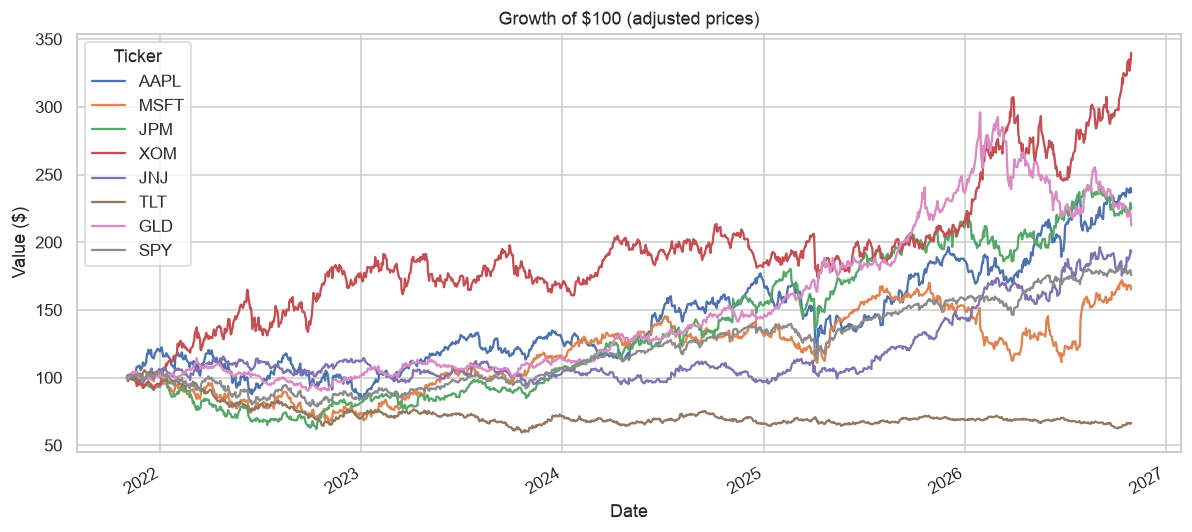

In [36]:
# Normalise every price to start at 100 so they are easy to compare
(prices / prices.iloc[0] * 100).plot(figsize=(11, 5), title="Growth of $100 (adjusted prices)")
plt.ylabel("Value ($)")
plt.tight_layout(); plt.savefig(IMG + "normalized_prices.png"); plt.show()

## 3. Returns, volatility and risk
Daily return = today's price / yesterday's price − 1. We annualise using 252 trading days.

In [ ]:
returns = prices.pct_change().dropna()

stats = pd.DataFrame({
    "Annual Return (avg)": returns.mean() * TRADING_DAYS,
    "Annual Volatility":   returns.std() * np.sqrt(TRADING_DAYS),
})
stats["Return / Risk"] = stats.iloc[:, 0] / stats.iloc[:, 1]
stats.sort_values("Return / Risk", ascending=False).style.format("{:.2f}")

In [ ]:
# Calendar-year returns for each asset
yearly = prices.resample("YE").last().pct_change().dropna(how="all")
yearly.index = yearly.index.year
yearly.style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)

### Correlation heatmap
Low or negative correlation = better diversification (assets don't all fall at the same time).

In [ ]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(returns.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation of Daily Returns")
plt.tight_layout(); plt.savefig(IMG + "correlation_heatmap.png"); plt.show()

In [ ]:
cumulative = (1 + returns).cumprod() - 1
cumulative.plot(figsize=(11, 5), title="Cumulative Returns by Asset")
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout(); plt.savefig(IMG + "cumulative_returns_assets.png"); plt.show()

## 4. Train / test split and risk-free rate
To be honest about performance, the optimiser only "sees" the training data. We then hold those weights fixed and measure results on the test period it has never seen.

The risk-free rate (for the Sharpe ratio) is the average 13-week US T-bill yield (`^IRX`) over each period.

In [ ]:
train_returns = returns.loc[:TRAIN_END, ASSETS]
test_prices   = prices.loc[TEST_START:]

rf_train = load_risk_free_rate(START, TRAIN_END)
rf_test  = load_risk_free_rate(TEST_START, END)
print(f"Training: {train_returns.index[0].date()} to {train_returns.index[-1].date()}  ({len(train_returns)} days), rf = {rf_train:.2%}")
print(f"Test:     {test_prices.index[0].date()} to {test_prices.index[-1].date()}  ({len(test_prices)} days), rf = {rf_test:.2%}")

## 5. Mean-variance optimisation (Max-Sharpe portfolio)
`scipy.optimize.minimize` searches for the weights that maximise *(expected return − risk-free rate) / volatility*, subject to: weights sum to 100%, no short selling, each weight ≤ 40%.

In [ ]:
w_sharpe = pd.Series(max_sharpe_weights(train_returns, rf=rf_train, max_weight=MAX_WEIGHT), index=ASSETS)
w_equal  = pd.Series(1 / len(ASSETS), index=ASSETS)

weights_table = pd.DataFrame({"Equal-Weight": w_equal, "Max-Sharpe": w_sharpe})
weights_table.style.format("{:.1%}")

### Efficient frontier (training data)
Each grey dot is a random portfolio. The line is the *efficient frontier*: the lowest risk possible for each level of return. The star is our Max-Sharpe portfolio.

In [ ]:
_, rand_ret, rand_vol = random_portfolios(train_returns, n=5000)
frontier = np.array(efficient_frontier(train_returns, n_points=40, max_weight=MAX_WEIGHT))

mean, cov = train_returns.mean().values, train_returns.cov().values
ms_ret, ms_vol = portfolio_stats(w_sharpe.values, mean, cov)
eq_ret, eq_vol = portfolio_stats(w_equal.values, mean, cov)

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rand_vol, rand_ret, c=(rand_ret - rf_train) / rand_vol, cmap="viridis", s=6, alpha=0.5)
plt.colorbar(sc, label="Sharpe ratio")
ax.plot(frontier[:, 0], frontier[:, 1], "k-", lw=2, label="Efficient frontier (max 40% per asset)")
ax.scatter(ms_vol, ms_ret, marker="*", s=350, c="red", label="Max-Sharpe", zorder=5)
ax.scatter(eq_vol, eq_ret, marker="D", s=90, c="orange", label="Equal-Weight", zorder=5)
for t in ASSETS:  # individual assets
    r, v = train_returns[t].mean() * TRADING_DAYS, train_returns[t].std() * np.sqrt(TRADING_DAYS)
    ax.scatter(v, r, c="black", s=25); ax.annotate(t, (v, r), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Annual volatility"); ax.set_ylabel("Annual expected return")
ax.set_title("Efficient Frontier – Training Period (Nov 2021 – Oct 2023)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(IMG + "efficient_frontier.png"); plt.show()

## 6. Backtest on the out-of-sample test period
Both portfolios start at their target weights, drift with prices during the month, and are rebalanced back to target at each month end (paying 5 bps on the traded amount). SPY is simply bought and held.

In [ ]:
bt = pd.DataFrame({
    "Equal-Weight (monthly)": backtest_rebalanced(test_prices[ASSETS], w_equal,  cost_bps=COST_BPS),
    "Max-Sharpe (monthly)":   backtest_rebalanced(test_prices[ASSETS], w_sharpe, cost_bps=COST_BPS),
    "SPY Buy & Hold":         buy_and_hold(test_prices, BENCHMARK),
})
bt.head()

### Performance summary
- **Annual Return:** compound annual growth rate (CAGR)
- **Sharpe Ratio:** excess return per unit of risk (higher is better)
- **Max Drawdown:** worst fall from a previous peak (closer to 0 is better)

In [ ]:
summary = summary_table(bt, rf=rf_test)
summary.to_csv("images/summary_metrics.csv")
summary.style.format({"Annual Return": "{:.2%}", "Annual Volatility": "{:.2%}",
                      "Sharpe Ratio": "{:.2f}", "Max Drawdown": "{:.2%}", "Total Return": "{:.2%}"})

In [ ]:
growth = 10_000 * (1 + bt).cumprod()
ax = growth.plot(figsize=(11, 5.5), lw=2, title="Growth of $10,000 – Out-of-Sample Test Period")
ax.set_ylabel("Portfolio value ($)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout(); plt.savefig(IMG + "cumulative_returns_comparison.png"); plt.show()

In [ ]:
dd = bt.apply(drawdown_series)
fig, ax = plt.subplots(figsize=(11, 4.5))
for col in dd:
    ax.plot(dd.index, dd[col], lw=1.4, label=col)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Drawdowns – Out-of-Sample Test Period"); ax.set_ylabel("Below previous peak")
ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(IMG + "drawdowns.png"); plt.show()

In [ ]:
# Rolling 6-month Sharpe ratio: is performance consistent over time?
window = 126
rolling_sharpe = ((bt.rolling(window).mean() - rf_test / TRADING_DAYS)
                  / bt.rolling(window).std() * np.sqrt(TRADING_DAYS))
rolling_sharpe.plot(figsize=(11, 4.5), title="Rolling 6-Month Sharpe Ratio")
plt.axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.savefig(IMG + "rolling_sharpe.png"); plt.show()

## 7. Bonus: what if we had known the future? (in-sample check)
For comparison, here are the Max-Sharpe weights estimated on the **test** period itself. The gap between these and the training weights shows why out-of-sample testing matters: optimal weights change a lot over time, so in-sample backtests usually look too good.

In [ ]:
w_hindsight = pd.Series(max_sharpe_weights(test_prices[ASSETS].pct_change().dropna(),
                                           rf=rf_test, max_weight=MAX_WEIGHT), index=ASSETS)
pd.DataFrame({"Trained on 2021-23 (used)": w_sharpe, "Hindsight 2023-26": w_hindsight}).style.format("{:.1%}")

## 8. Conclusions
The summary is generated from the numbers above:

In [ ]:
best_sharpe = summary["Sharpe Ratio"].idxmax()
best_dd     = summary["Max Drawdown"].idxmax()   # closest to zero
best_ret    = summary["Annual Return"].idxmax()
print(f"Highest annual return : {best_ret} ({summary.loc[best_ret, 'Annual Return']:.1%})")
print(f"Best Sharpe ratio     : {best_sharpe} ({summary.loc[best_sharpe, 'Sharpe Ratio']:.2f})")
print(f"Smallest max drawdown : {best_dd} ({summary.loc[best_dd, 'Max Drawdown']:.1%})")

**Key takeaways**
- **Diversification works:** stocks, TLT and GLD have low correlations, so the simple equal-weight portfolio had roughly 1/3 less volatility than SPY and a much smaller worst drawdown, while still keeping up on return. It had the best Sharpe ratio.
- **Optimisation is a double-edged sword:** the Max-Sharpe portfolio ended up concentrated in only a few assets (it hit the 40% cap). It earned the highest return out-of-sample, but with more risk than equal-weight, so a lower Sharpe. Optimal weights depend heavily on the training period (see the hindsight comparison).
- **Always test out-of-sample:** an in-sample backtest would have used the "hindsight" weights and looked unrealistically good.

**Limitations & next steps**
- Past returns are a noisy estimate of future returns; try shrinkage estimators (Ledoit-Wolf) or a minimum-variance portfolio, which only needs the covariance matrix.
- Re-estimate weights on a rolling window (walk-forward optimisation).
- Add more assets (international equities, REITs) and taxes / slippage.